# E02 · Why a lens computes a Fourier transform

A lens sorts plane waves into focal spots. A second lens turns that spectrum back into an image—and lets you edit it along the way.

<!-- course-motivation:start -->
## Why learn this?

**Can you filter an image before the camera sees it?**

Suppose you want to suppress fine texture, emphasize boundaries, or reveal a nearly invisible transparent object. A lens gives you access to the spatial frequencies of the field, so a mask placed between two lenses can change which features reach the camera.

**What you gain:** Choose where to place a filter and predict its effect on amplitude and phase objects, including which image detail the filter removes.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Follow a position-dependent phase multiplying a complex field. Used here: A thin lens changes the wavefront before free-space propagation. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Fourier transforms and convolution:** Recognize spatial frequency, the Fourier shift property, and two successive transforms. Used here: These connect illumination direction, focal-plane position, and the inverted 4f image. [Review: TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/). Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.

**Python preparation:** Use 2D FFTs and distinguish a frequency-bin coordinate from a focal-plane coordinate.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Connect a lens's Fourier plane to spatial filtering and phase contrast.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Convert transverse spatial frequency into a focal-plane coordinate.
- Explain why two Fourier transforms invert an image.
- Predict how Fourier-plane masks change amplitude and phase objects.

**Model:** Coherent monochromatic scalar illumination, ideal paraxial lenses, and thin Fourier masks. The focal-spot panel uses a Gaussian entrance field. The 4f panel is a periodic sampled field; no aberrations, finite detector pixels, or noise are included.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e02_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Put physical units on a Fourier axis

A paraxial lens maps spatial frequency $f_x$ to $x_f=\lambda f f_x$.
A finite entrance field makes a finite-width spot. Tilting it changes the position,
while increasing focal length stretches the entire focal-plane coordinate scale.
**Predict:** double f before rerunning. Which plotted distance should double?

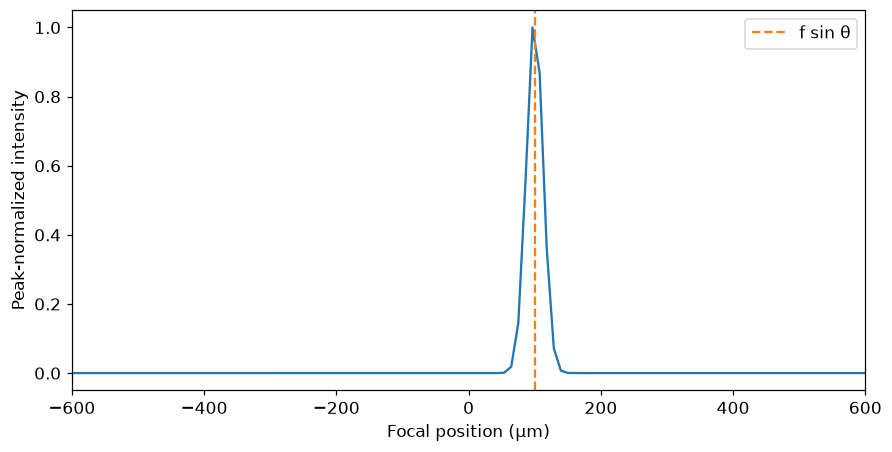

Predicted / sampled peak: 99.99833334166665 96.6796875 μm; focal sample spacing: 10.7421875


In [2]:
wavelength, focal_length = .55, 10000.  # μm
tilt = .01  # rad
n,dx = 512,1.
x=(np.arange(n)-n//2)*dx
field=np.exp(-(x/70)**2)*np.exp(2j*np.pi*np.sin(tilt)*x/wavelength)
F=lambda u:np.fft.fftshift(np.fft.fftn(np.fft.ifftshift(u),norm="ortho"))
FH=lambda u:np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(u),norm="ortho"))
frequency=np.fft.fftshift(np.fft.fftfreq(n,dx))
focal_x=wavelength*focal_length*frequency
spot=abs(F(field))**2
prediction=focal_length*np.sin(tilt)
peak_position=focal_x[np.argmax(spot)]
assert abs(peak_position-prediction)<=abs(focal_x[1]-focal_x[0])/2+1e-9
assert abs(np.sum(spot)/np.sum(abs(field)**2)-1)<1e-12
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(focal_x,spot/spot.max());ax.axvline(prediction,color="tab:orange",ls="--",label="f sin θ")
ax.set(xlim=(-600,600),xlabel="Focal position (μm)",ylabel="Peak-normalized intensity");ax.legend()
show(fig,"01-directions-to-positions")
print("Predicted / sampled peak:",prediction,peak_position,"μm; focal sample spacing:",focal_x[1]-focal_x[0])

## 2 · A 4f system transforms twice

The first lens transforms the complex field, a mask multiplies it, and the second lens
transforms again. Two forward transforms reverse the periodic spatial indices.
For coherent illumination, filter the field first and square only at the detector.

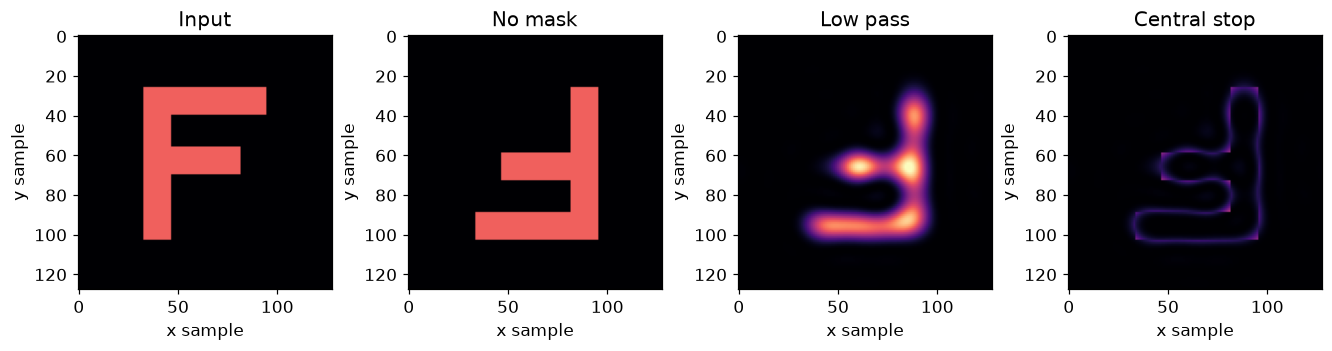

4f reversal assertion passed.


In [3]:
n=128
yy,xx=np.mgrid[:n,:n]/n
letter=((xx>.25)&(xx<.36)&(yy>.2)&(yy<.8))|((xx>.25)&(xx<.74)&(yy>.2)&(yy<.31))|((xx>.25)&(xx<.64)&(yy>.43)&(yy<.54))
object_field=letter.astype(complex)
f=np.fft.fftshift(np.fft.fftfreq(n));FX,FY=np.meshgrid(f,f);radius=np.hypot(FX,FY)
masks={"No mask":np.ones((n,n)),"Low pass":radius<.04,"Central stop":radius>.04}
index=(-np.arange(n))%n
expected=object_field[np.ix_(index,index)]
assert np.max(abs(F(F(object_field))-expected))<1e-12
fig,ax=plt.subplots(1,4,figsize=(12,3.6))
ax[0].imshow(abs(object_field)**2,vmin=0,vmax=1.5,cmap="magma");ax[0].set_title("Input")
for a,(name,mask) in zip(ax[1:],masks.items()):
    image=F(mask*F(object_field))
    a.imshow(abs(image)**2,vmin=0,vmax=1.5,cmap="magma");a.set_title(name)
for a in ax:a.set(xlabel="x sample",ylabel="y sample")
show(fig,"02-fourier-masks")
print("4f reversal assertion passed.")

## 3 · Rotate the background of a phase object

A weak phase object has $U \approx 1+i\phi$. A small phase disk changes the relative
phase of the central background and scattered components. This can reveal structure,
but the finite disk also modifies low-frequency scattering: it is not an exact phase map.

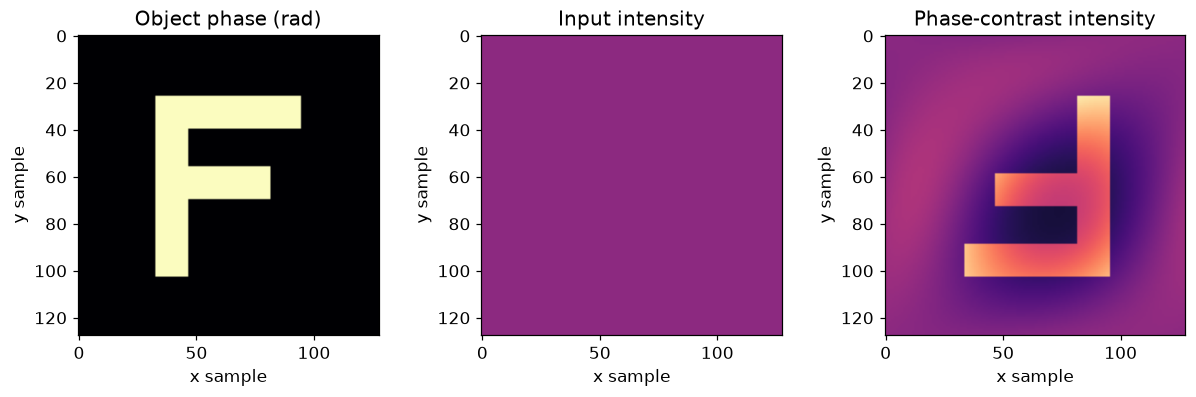

In [4]:
phase_object=np.exp(.65j*letter)
phase_disk=np.exp(1j*np.pi/2*(radius<1.5/n))
revealed=F(phase_disk*F(phase_object))
assert np.ptp(abs(phase_object)**2)<1e-12
assert np.ptp(abs(revealed)**2)>.1
fig,ax=plt.subplots(1,3,figsize=(11,3.5))
for a,v,title in zip(ax,[.65*letter,abs(phase_object)**2,abs(revealed)**2],["Object phase (rad)","Input intensity","Phase-contrast intensity"]):
    a.imshow(v,cmap="magma",vmin=0,vmax=2.5 if "intensity" in title.lower() else .65)
    a.set(title=title,xlabel="x sample",ylabel="y sample")
show(fig,"03-phase-contrast")

## Optional extension · Check the quadratic-phase cancellation

At the back focal plane of a lens, an object placed immediately against the lens produces
a Fourier transform with a remaining output quadratic phase. The Fresnel kernel below
is evaluated directly and compared with the FFT on its correct physical output grid.
A front-focal-plane placement cancels this additional coordinate phase; it matters for
complex-field comparisons even when intensity pictures agree.

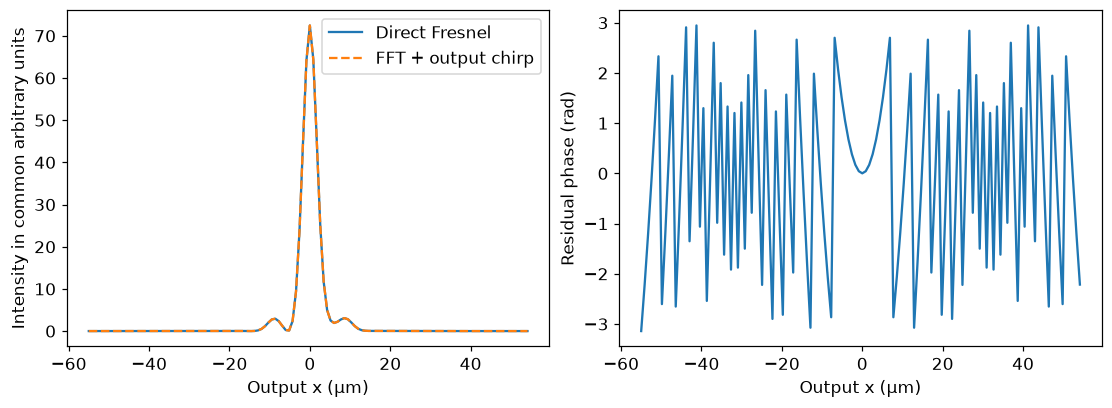

Direct-kernel/FFT field relative error: 5.563640690787443e-15


In [5]:
size,spacing,f_lens,lam=128,.5,100.,.55
xin=(np.arange(size)-size//2)*spacing
input_field=np.exp(-(xin/5)**2)*np.exp(.4j*np.sin(xin))
fx=np.fft.fftshift(np.fft.fftfreq(size,spacing))
xout=lam*f_lens*fx
k=2*np.pi/lam
lens=np.exp(-1j*k*xin*xin/(2*f_lens))
kernel=np.exp(1j*k*(xout[:,None]-xin[None,:])**2/(2*f_lens))
direct=kernel@(input_field*lens)*spacing
fourier=(F(input_field)*np.sqrt(size)*spacing)*np.exp(1j*k*xout*xout/(2*f_lens))
relative=np.linalg.norm(direct-fourier)/np.linalg.norm(direct)
assert relative<1e-12
fig,ax=plt.subplots(1,2,figsize=(10,3.6))
ax[0].plot(xout,abs(direct)**2,label="Direct Fresnel");ax[0].plot(xout,abs(fourier)**2,"--",label="FFT + output chirp")
ax[0].set(xlabel="Output x (μm)",ylabel="Intensity in common arbitrary units");ax[0].legend()
ax[1].plot(xout,np.angle(np.exp(1j*k*xout*xout/(2*f_lens))))
ax[1].set(xlabel="Output x (μm)",ylabel="Residual phase (rad)")
show(fig,"04-fresnel-check")
print("Direct-kernel/FFT field relative error:",relative)

## A short lab report

**1. Calibrate the Fourier plane.** Predict the focal coordinate of a known spatial frequency for two focal lengths.

**2. Compare three masks.** Save unfiltered, low-pass, and central-stop images with the same intensity scale.

**3. Make phase visible.** Compare a weak phase object before and after a central π/2 phase shift.

### Worked reasoning

**Calibrate the Fourier plane.** Use x_f = λf fₓ with consistent units. The frequency grid and physical focal grid are not the same axis.

**Compare three masks.** The mask acts on the complex field spectrum. Squaring after filtering makes coherent image formation nonlinear in input intensity.

**Make phase visible.** The small scattered field interferes differently with the rotated background. Finite disk size and strong phase shifts limit the weak-object interpretation.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OpenCourseWare · Spatial filtering and lens transforms](https://ocw.mit.edu/courses/2-71-optics-spring-2009/resources/lecture-18-spatial-filtering-lens-transfer-functions-transforms/)
- [TU Delft · Wavefield propagation](https://qiweb.tudelft.nl/aoi/wavefieldpropagation/wavefieldpropagation/)
- [NumPy · Fourier transforms and normalization](https://numpy.org/doc/stable/reference/routines.fft.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e02_figures.zip


/tmp/optics-notebooks-xppq4daw/E02/e02_figures.zip